#  Bulk RNA-seq Gene Set Enrichment Analysis(GSEA)
 GSEA was performed using a ranked gene list based on the DESeq2 Wald statistic (stat) to identify biological pathways associated with type 2 diabetes.

# 1. Import libraries and set project paths

In [1]:
# Import
import pandas as pd
import numpy as np
from pathlib import Path
import gseapy as gp
import yaml
import matplotlib.pyplot as plt


# Find the project folder
PROJECT_ROOT = Path.cwd().resolve()

if not (PROJECT_ROOT / "config.yaml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parents[1]

# Read the team config file
with open(PROJECT_ROOT / "config.yaml", encoding="utf-8") as file:
    config = yaml.safe_load(file)

# Input paths from config.yaml
DE_FILE = PROJECT_ROOT / config["inputs"]["differential_expression_results"]
GENE_INFO_FILE = PROJECT_ROOT / config["inputs"]["gene_annotation"]

# Output paths from config.yaml
OUT = PROJECT_ROOT / config["gsea"]["tables"]
FIGURES_DIR = PROJECT_ROOT / config["gsea"]["figures"]
NATIVE_OUTPUT_DIR = PROJECT_ROOT / config["gsea"]["native_output"]

OUT.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
NATIVE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load GSEA settings from the shared project configuration.
GENE_SET = config["gsea"]["gene_set"]
SEED = config["gsea"]["seed"]
MIN_SIZE = config["gsea"]["min_size"]
MAX_SIZE = config["gsea"]["max_size"]
PERMUTATION_NUM = config["gsea"]["permutation_num"]
TOP_PLOTS = config["gsea"].get("top_plots", 10)

# Verify paths
print("Project root:", PROJECT_ROOT)
print("DE file:", DE_FILE, "| Exists:", DE_FILE.exists())
print("Gene annotation:", GENE_INFO_FILE, "| Exists:", GENE_INFO_FILE.exists())
print("GSEA tables:", OUT.resolve())
print("GSEA figures:", FIGURES_DIR.resolve())
print("GSEA native output:", NATIVE_OUTPUT_DIR.resolve())


Project root: /home/areejoamr/projects/islet-t2d-project/bulk-rna-project
DE file: /home/areejoamr/projects/islet-t2d-project/bulk-rna-project/results/tables/differential_expression/differential_expression_results.csv | Exists: True
Gene annotation: /home/areejoamr/projects/islet-t2d-project/bulk-rna-project/reference/STAR_index_GRCh38/geneInfo.tab | Exists: True
GSEA tables: /home/areejoamr/projects/islet-t2d-project/bulk-rna-project/results/tables/gsea
GSEA figures: /home/areejoamr/projects/islet-t2d-project/bulk-rna-project/results/figures/gsea
GSEA native output: /home/areejoamr/projects/islet-t2d-project/bulk-rna-project/results/gsea_native_output


# 2. Load differential-expression results and gene annotation

In [2]:
# Read the input tables; the analysis steps below are unchanged.
df = pd.read_csv(
    DE_FILE,
    skiprows=1,
    header=None,
    names=[
        "gene_id", "baseMean", "log2FoldChange",
        "lfcSE", "stat", "pvalue", "padj"
    ]
)
gene_info = pd.read_csv(
    GENE_INFO_FILE,
    sep="\t",
    header=None,
    skiprows=1
)


gene_info = gene_info.iloc[:, :3].copy()
gene_info.columns = ["gene_id", "gene_name", "gene_type"]


display(df.head())
display(gene_info.head())



,gene_id,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
0,ENSG00000227232.5,23.089821,0.543811,0.547949,0.992449,0.320979,0.831170
1,ENSG00000278267.1,6.881551,0.508027,0.708373,0.717173,0.473267,NaN
2,ENSG00000238009.6,1.153895,0.505383,1.603992,0.315078,0.752702,NaN
3,ENSG00000268903.1,19.562427,0.693730,0.740279,0.937119,0.348698,0.841396
4,ENSG00000269981.1,14.007763,0.202276,0.917064,0.220569,0.825428,0.976299


,gene_id,gene_name,gene_type
0,ENSG00000290825.1,DDX11L2,lncRNA
1,ENSG00000223972.6,DDX11L1,transcribed_unprocessed_pseudogene
2,ENSG00000227232.5,WASH7P,unprocessed_pseudogene
3,ENSG00000278267.1,MIR6859-1,miRNA
4,ENSG00000243485.5,MIR1302-2HG,lncRNA


3. Map gene IDs and prepare the ranked gene list

In [3]:
# Remove Ensembl version suffixes before matching gene IDs.
def clean_gene_id(series):
    return series.astype(str).str.replace(r"\.\d+$", "", regex=True)

df["gene_id_clean"] = clean_gene_id(df["gene_id"])
gene_info["gene_id_clean"] = clean_gene_id(gene_info["gene_id"].astype(str))

gene_info["gene_name"] = gene_info["gene_name"].astype(str).str.strip()
gene_info.loc[
    gene_info["gene_name"].isin(["", "nan", "None"]),
    "gene_name"
] = np.nan


mapping = (
    gene_info.dropna(subset=["gene_name"])
    .drop_duplicates("gene_id_clean")
    .set_index("gene_id_clean")["gene_name"]
)

df["gene_name"] = df["gene_id_clean"].map(mapping)
df["stat"] = pd.to_numeric(df["stat"], errors="coerce")

n_before = len(df)

mapped = df.dropna(subset=["gene_name", "stat"]).copy()
mapped = mapped[np.isfinite(mapped["stat"])]



mapped["abs_stat"] = mapped["stat"].abs()
mapped = mapped.sort_values("abs_stat", ascending=False).drop_duplicates("gene_name")
mapped = mapped.sort_values("stat", ascending=False)

ranking = mapped[["gene_name", "stat"]].rename(columns={"gene_name": "gene_name", "stat": "stat"})
if len(ranking) < 2:
    raise ValueError("Too few mapped genes with finite stat values. Check the gene ID mapping and input files.")

ranking.to_csv(OUT / "ranked_genes.tsv", sep="\t", header=False, index=False)
mapped.to_csv(OUT / "mapped_DE_genes.csv", index=False)

mapping_summary = pd.DataFrame({
    "metric": [
        "input_DE_rows", "rows_with_gene_symbol_and_stat_before_deduplication",
        "rows_in_final_ranked_list", "rows_without_gene_symbol_or_stat",
        "duplicate_symbols_removed", "missing_stat_in_input", "non_finite_stat_removed"
    ],
    "value": [
        n_before, int(df.dropna(subset=["gene_name", "stat"]).shape[0]),
        len(ranking), int(df[["gene_name", "stat"]].isna().any(axis=1).sum()),
        int(df.dropna(subset=["gene_name", "stat"]).shape[0] - len(ranking)),
        int(pd.to_numeric(df["stat"], errors="coerce").isna().sum()),
        int((~np.isfinite(pd.to_numeric(df["stat"], errors="coerce").fillna(np.nan))).sum())
    ]
})
mapping_summary.to_csv(OUT / "input_mapping_summary.csv", index=False)
display(mapping_summary)
print("Ranked genes saved:", len(ranking))

,metric,value
0,input_DE_rows,33432
1,rows_with_gene_symbol_and_stat_before_deduplic...,33432
2,rows_in_final_ranked_list,33256
3,rows_without_gene_symbol_or_stat,0
4,duplicate_symbols_removed,176
5,missing_stat_in_input,0
6,non_finite_stat_removed,0


Ranked genes saved: 33256


## 4. Run Preranked GSEA

In [4]:
# Run preranked GSEA using the shared project settings.
pre_res = gp.prerank(
    rnk=ranking,
    gene_sets=GENE_SET,
    seed=SEED,
    outdir=str(NATIVE_OUTPUT_DIR),
    min_size=MIN_SIZE,
    max_size=MAX_SIZE,
    permutation_num=PERMUTATION_NUM,
    graph_num=TOP_PLOTS,
    verbose=True
)

# Save the complete GSEA results.
results = pre_res.res2d.copy()
results.to_csv(OUT / "GSEA_all_pathways.csv", index=False)

# Save all GSEA results
results = pre_res.res2d.copy()
results.to_csv(OUT / "GSEA_all_pathways.csv", index=False)

results["FDR q-val"] = pd.to_numeric(results["FDR q-val"], errors="coerce")
significant = results[results["FDR q-val"] < 0.05].copy()
significant.to_csv(OUT / "GSEA_significant_pathways_FDR_lt_0.05.csv", index=False)


2026-10-29 00:29:26,436 [WARNING] Duplicated values found in preranked stats: 22.33% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-10-29 00:29:26,438 [INFO] Parsing data files for GSEA.............................
2026-10-29 00:29:26,440 [INFO] Enrichr library gene sets already downloaded in: /home/areejoamr/.cache/gseapy, use local file
2026-10-29 00:29:26,573 [INFO] 2774 gene_sets have been filtered out when max_size=500 and min_size=15
2026-10-29 00:29:26,575 [INFO] 2569 gene_sets used for further statistical testing.....
2026-10-29 00:29:26,575 [INFO] Start to run GSEA...Might take a while..................
2026-10-29 00:30:55,291 [INFO] Start to generate gseapy reports, and produce figures...
2026-10-29 00:30:55,292 [INFO] Congratulations. GSEApy runs successfully................




# 5. Identify Significant Pathways (FDR < 0.05)

Filter the GSEA results to retain statistically significant pathways for downstream interpretation and visualization.


In [ ]:
# Convert result columns to numeric and select significant pathways.
results["NES"] = pd.to_numeric(results["NES"], errors="coerce")
results["FDR q-val"] = pd.to_numeric(
    results["FDR q-val"], errors="coerce"
)
significant = results.loc[
    results["FDR q-val"] < 0.05
].dropna(subset=["NES"]).copy()

# Save the significant pathway table.
significant.to_csv(
    OUT / "GSEA_significant_pathways_FDR_lt_0.05.csv",
    index=False
)

display(significant)



,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,prerank,Extracellular Matrix Organization (GO:0030198),0.620471,2.529312,0.0,0.000000,0.0,83/175,12.78%,COL7A1;MMP14;ADAMTS10;COL15A1;MMP7;ITGA2;ADAMT...
1,prerank,Integrin-Mediated Signaling Pathway (GO:0007229),0.66445,2.500027,0.0,0.000000,0.0,39/85,9.74%,SEMA7A;ITGA2;ADAMTS1;NRP1;ITGB6;CDH17;ITGB1;ZY...
2,prerank,Positive Regulation of Extrinsic Apoptotic Sig...,0.731448,2.388517,0.0,0.000000,0.0,18/39,9.74%,INHBA;LTB;RET;PMAIP1;TNFSF10;PYCARD;BID;TNFSF1...
3,prerank,Positive Regulation of Cell-Substrate Adhesion...,0.651102,2.369804,0.0,0.000000,0.0,29/70,8.56%,OLFM4;FGB;S100A10;NRP1;CX3CL1;FLNA;PDGFB;CSF1;...
4,prerank,Cellular Response to Amino Acid Starvation (GO...,-0.65307,-2.362659,0.0,0.000000,0.0,25/46,21.68%,GPR155;RRAGD;TFEB;PRKCH;GDNF;IMPACT;PRKD1;EIF2...
...,...,...,...,...,...,...,...,...,...,...
618,prerank,Cardiac Muscle Tissue Development (GO:0048738),0.464132,1.584986,0.009434,0.048463,1.0,18/50,22.49%,GJA1;TBX2;MYL7;ADAMTS9;NOTCH2;SLC25A37;SGCZ;BM...
619,prerank,Response to Peptide Hormone (GO:0043434),0.470198,1.583583,0.011905,0.048859,1.0,14/52,8.00%,IGFBP5;TRIM16;MEAK7;STAT2;IRS1;ZFP36L1;POMC;SR...
620,prerank,Positive Regulation of Leukocyte Cell-Cell Adh...,0.475863,1.583094,0.0032,0.048988,1.0,17/46,17.88%,IL6;HAS2;PYCARD;TNF;SIRPA;HLA-DOA;RELA;CCL2;TN...
621,prerank,Learning (GO:0007612),0.479752,1.582001,0.014241,0.049405,1.0,15/43,16.16%,RELN;SYT12;EPHB2;ATXN1;CNTNAP2;TLR2;LGMN;SHANK...



# 6. Plot Top 5 Positive and Top 5 Negative GSEA Pathways

Select the five significant pathways with the highest positive NES and the five with the lowest negative NES, then visualize their enrichment curves in one combined figure.


,Term,NES,FDR q-val
0,Extracellular Matrix Organization (GO:0030198),2.529312,0.000000
1,Integrin-Mediated Signaling Pathway (GO:0007229),2.500027,0.000000
2,Positive Regulation of Extrinsic Apoptotic Sig...,2.388517,0.000000
3,Positive Regulation of Cell-Substrate Adhesion...,2.369804,0.000000
5,Regulation of Extrinsic Apoptotic Signaling Pa...,2.359954,0.000000
4,Cellular Response to Amino Acid Starvation (GO...,-2.362659,0.000000
20,Response to Amino Acid Starvation (GO:1990928),-2.265509,0.000837
93,Cytoplasmic Translation (GO:0002181),-2.032610,0.037955
108,Cellular Response to Acid Chemical (GO:0071229),-2.004863,0.043745
110,Chaperone-Mediated Protein Complex Assembly (G...,-2.001996,0.037675


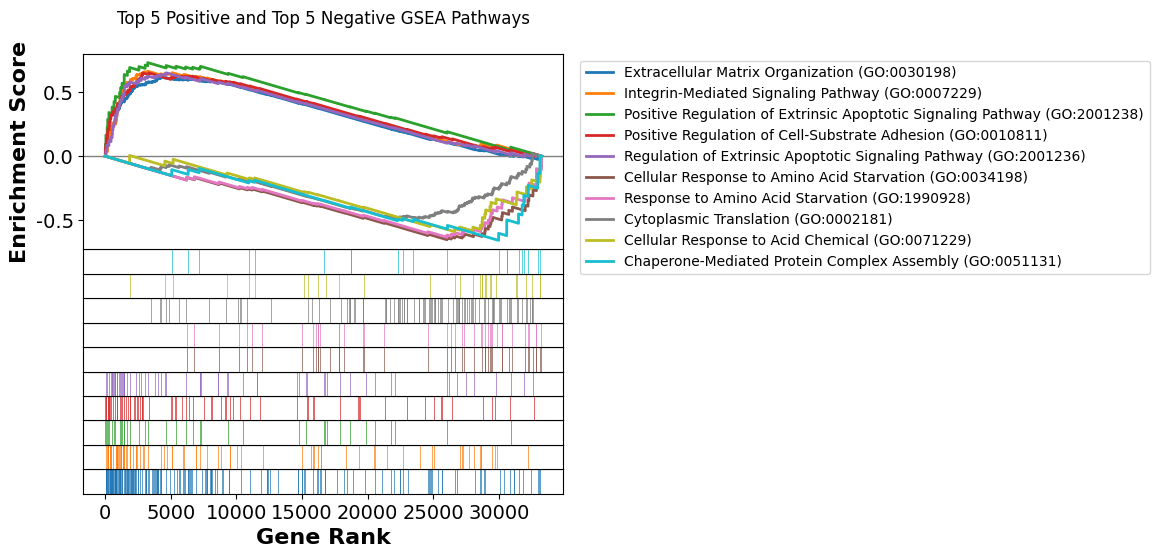

In [13]:
# Select the top 5 significant pathways in each NES direction.
positive = significant[significant["NES"] > 0].nlargest(5, "NES")
negative = significant[significant["NES"] < 0].nsmallest(5, "NES")

if len(positive) < 5 or len(negative) < 5:
    raise ValueError(
        f"Expected 5 positive and 5 negative significant pathways; "
        f"found {len(positive)} positive and {len(negative)} negative."
    )

top_pathways = pd.concat([positive, negative])

# Save the selected pathways for reporting.
top_pathways.to_csv(
    OUT / "GSEA_top5_positive_negative_pathways.csv",
    index=False
)

# Plot the 10 running enrichment-score curves in one figure.
terms = top_pathways["Term"].astype(str).tolist()
axes = pre_res.plot(
    terms,
    show_ranking=False,
    figsize=(14, 8),
    legend_kws={"loc": "upper left", "bbox_to_anchor": (1.02, 1)}
)

# GSEApy returns the Matplotlib axes; obtain the figure from the first axis.
fig = axes
fig.suptitle("Top 5 Positive and Top 5 Negative GSEA Pathways")
fig.savefig(
    FIGURES_DIR / "GSEA_top5_positive_negative_curves.png",
    dpi=300, bbox_inches="tight"
)
fig.savefig(
    FIGURES_DIR / "GSEA_top5_positive_negative_curves.pdf",
    bbox_inches="tight"
)

display(top_pathways[["Term", "NES", "FDR q-val"]])
plt.show()
plt.close(fig)

